In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from time import perf_counter
from sklearn.metrics import mean_absolute_error, mean_squared_error

root = Path.home() / "Desktop/Chooser_Option_Research"
fig_dir = root / "04_Reports/weekly/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

dataset = pd.read_csv(
    root / "02_Data/processed/W06_Synthetic_Heston_Dataset.csv"
)

bundle = joblib.load(
    root / "03_Code/models/W07_Selected_Pricing_Model.joblib"
)

name = bundle["name"]
model = bundle["model"]
features = bundle["features"]

def predict_price(frame):
    pred = model.predict(frame[features]) * frame["S"].to_numpy()

    if name != "RF Direct":
        pred += frame["bsm_price"].to_numpy()

    return pred

rows = []

for split in ["test", "stress"]:
    sample = dataset[dataset["split"] == split].copy()

    actual = sample["heston_price"]
    predicted = predict_price(sample)

    for method, result in [
        ("BSM", sample["bsm_price"]),
        (name, predicted)
    ]:
        rows.append({
            "Split": split,
            "Method": method,
            "MAE": mean_absolute_error(actual, result),
            "RMSE": np.sqrt(
                mean_squared_error(actual, result)
            ),
            "Median MC SE": sample["mc_se"].median()
        })

robustness_df = pd.DataFrame(rows)

display(robustness_df.round(4))

,Split,Method,MAE,RMSE,Median MC SE
0,test,BSM,4.4915,5.9454,0.1016
1,test,HGB Correction,1.0320,1.4625,0.1016
2,stress,BSM,4.1369,5.5649,0.1597
3,stress,HGB Correction,1.6351,2.1591,0.1597


In [5]:
# W08 — where does the ML error increase?
robust_cases = dataset[dataset["split"].isin(["test", "stress"])].copy()
robust_cases["ml_price"] = predict_price(robust_cases)
robust_cases["abs_error"] = (
    robust_cases["ml_price"] - robust_cases["heston_price"]
).abs()
robust_cases["error_over_se"] = (
    robust_cases["abs_error"] / robust_cases["mc_se"].clip(lower=1e-12)
)

summary = robust_cases.groupby(
    ["split", "feller_met"], observed=True
).agg(
    n=("case_id", "size"),
    mae=("abs_error", "mean"),
    median_mc_se=("mc_se", "median"),
    median_error_to_se=("error_over_se", "median")
)

display(summary.round(4))
display(robust_cases.nlargest(10, "abs_error")[[
    "split", "case_id", "moneyness", "xi", "v0",
    "theta", "kappa", "feller_met", "abs_error", "mc_se"
]].round(4))

n     mae  median_mc_se  median_error_to_se
split  feller_met                                               
stress False        73  1.7010        0.1759              7.5762
       True         27  1.4570        0.1301              7.0059
test   False        30  0.9508        0.1576              4.2628
       True        120  1.0524        0.0921              8.0552

,split,case_id,moneyness,xi,v0,theta,kappa,feller_met,abs_error,mc_se
906,stress,906,1.2671,0.6320,0.0571,0.0202,2.1403,False,6.0580,0.2011
896,test,896,1.0696,0.2707,0.0207,0.0755,1.9650,True,5.8522,0.1256
959,stress,959,1.2116,0.6304,0.0170,0.1011,3.0884,True,5.3426,0.1870
956,stress,956,1.2953,0.5663,0.1001,0.0372,3.3844,False,5.1205,0.2321
764,test,764,1.1180,0.2462,0.0383,0.0888,0.9779,True,4.9825,0.0793
945,stress,945,1.3012,0.5912,0.0699,0.0286,1.4892,False,4.9379,0.2765
930,stress,930,1.2473,0.6179,0.0246,0.0956,2.6673,True,4.9039,0.1802
924,stress,924,1.3375,0.5500,0.0224,0.0873,1.7274,False,4.7774,0.1278
841,test,841,0.9956,0.4153,0.0181,0.0619,3.4617,True,4.6897,0.1023
988,stress,988,1.3300,0.5567,0.0972,0.0236,1.6533,False,4.4900,0.2895


,Feature,Importance,SD
3,r1,-0.0036,0.0061
5,q,0.0035,0.0066
4,r2,0.0127,0.0155
10,rho,0.0593,0.0229
1,T1,0.1351,0.0213
9,xi,0.1409,0.0462
2,T2,0.2892,0.0514
8,kappa,0.3505,0.0568
0,moneyness,0.8605,0.1321
7,theta,3.0639,0.2167


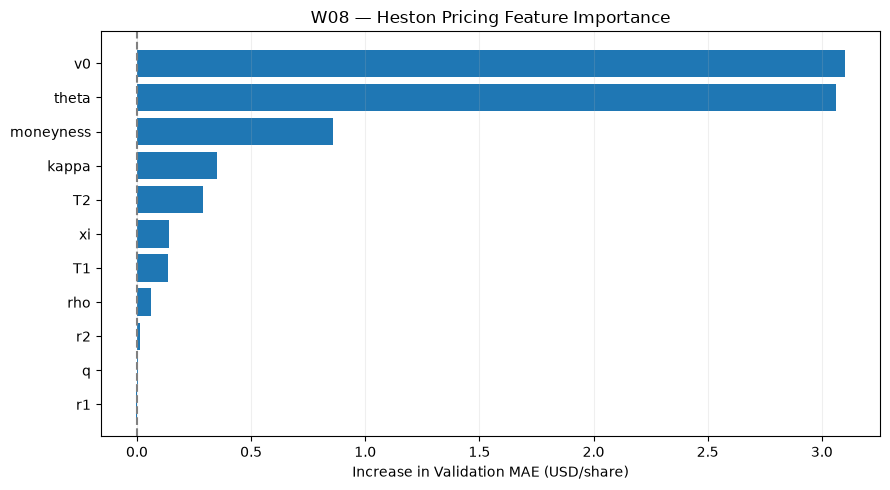

In [6]:
valid = dataset[
    dataset["split"] == "validation"
].copy()

actual = valid["heston_price"].to_numpy()

base_mae = mean_absolute_error(
    actual, predict_price(valid)
)

rng = np.random.default_rng(42)
records = []

for feature in features:
    increases = []

    for repeat in range(10):
        shuffled = valid.copy()

        shuffled[feature] = rng.permutation(
            shuffled[feature].to_numpy()
        )

        mae = mean_absolute_error(
            actual, predict_price(shuffled)
        )

        increases.append(mae - base_mae)

    records.append({
        "Feature": feature,
        "Importance": np.mean(increases),
        "SD": np.std(increases, ddof=1)
    })

importance_df = pd.DataFrame(records).sort_values(
    "Importance"
)

display(importance_df.round(4))

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

ax.axvline(0, color="gray", linestyle="--")
ax.set_xlabel("Increase in Validation MAE (USD/share)")
ax.set_title("W08 — Heston Pricing Feature Importance")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

fig.savefig(
    fig_dir / "W08_Heston_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,ML_Error,BSM_Error
Moneyness_Group,,
"(0.799, 0.9]",0.8775,2.3158
"(0.9, 1.0]",0.7210,4.6278
"(1.0, 1.1]",1.2475,5.6543
"(1.1, 1.2]",1.2805,5.3954


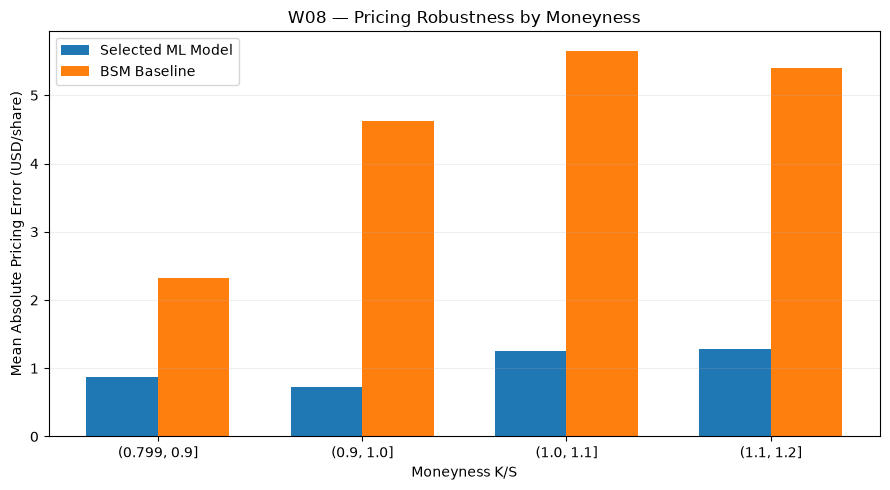

In [7]:
test = dataset[
    dataset["split"] == "test"
].copy()

test["ML_Price"] = predict_price(test)

test["ML_Error"] = (
    test["heston_price"] - test["ML_Price"]
).abs()

test["BSM_Error"] = (
    test["heston_price"] - test["bsm_price"]
).abs()

test["Moneyness_Group"] = pd.cut(
    test["moneyness"],
    bins=[0.8, 0.9, 1.0, 1.1, 1.2],
    include_lowest=True
)

grouped = test.groupby(
    "Moneyness_Group", observed=True
)[["ML_Error", "BSM_Error"]].mean()

display(grouped.round(4))

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(grouped))
width = 0.35

ax.bar(
    x-width/2, grouped["ML_Error"],
    width, label="Selected ML Model"
)

ax.bar(
    x+width/2, grouped["BSM_Error"],
    width, label="BSM Baseline"
)

ax.set_xticks(x)
ax.set_xticklabels(grouped.index.astype(str))

ax.set_xlabel("Moneyness K/S")
ax.set_ylabel("Mean Absolute Pricing Error (USD/share)")
ax.set_title("W08 — Pricing Robustness by Moneyness")
ax.grid(axis="y", alpha=0.2)
ax.legend()

plt.tight_layout()

fig.savefig(
    fig_dir / "W08_Pricing_Robustness_Moneyness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
from time import perf_counter

# Make this cell independent of the Moneyness plot above
runtime_sample = dataset.loc[dataset["split"] == "test"].iloc[:30].copy()
n = len(runtime_sample)

# Warm-up both inference modes
_ = predict_price(runtime_sample.iloc[[0]])
_ = predict_price(runtime_sample)

single_repeats = 3
start = perf_counter()
for _ in range(single_repeats):
    for j in range(n):
        _ = predict_price(runtime_sample.iloc[[j]])
single_ms = 1000*(perf_counter()-start)/(single_repeats*n)

batch_repeats = 30
start = perf_counter()
for _ in range(batch_repeats):
    _ = predict_price(runtime_sample)
batch_ms = 1000*(perf_counter()-start)/(batch_repeats*n)

recorded_mc_ms = runtime_sample["mc_seconds"].median()*1000

print(f"Row-by-row ML inference: {single_ms:.4f} ms/contract")
print(f"Batch ML inference:      {batch_ms:.4f} ms/contract")
print(f"Recorded Heston MC:      {recorded_mc_ms:.4f} ms/contract")
print(f"Row-by-row ratio (MC/ML): {recorded_mc_ms/single_ms:.1f}x")
print(f"Batch ratio (MC/ML):      {recorded_mc_ms/batch_ms:.1f}x")

Row-by-row ML inference: 13.9602 ms/contract
Batch ML inference:      0.4221 ms/contract
Recorded Heston MC:      45.2986 ms/contract
Row-by-row ratio (MC/ML): 3.2x
Batch ratio (MC/ML):      107.3x


In [9]:
from scipy.stats import norm

# Vectorized BSM helper: one-dimensional arrays are supported
def bs_value(S, K, T, r, q, sigma, kind):
    d1 = (np.log(S/K) + (r-q+0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    if kind == "call":
        return S*np.exp(-q*T)*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2)
    return K*np.exp(-r*T)*norm.cdf(-d2)-S*np.exp(-q*T)*norm.cdf(-d1)

def reprice_bsm_for_spot(frame):
    S, K = frame["S"].to_numpy(), frame["K"].to_numpy()
    T1, T2 = frame["T1"].to_numpy(), frame["T2"].to_numpy()
    r1, r2 = frame["r1"].to_numpy(), frame["r2"].to_numpy()
    q, sigma = frame["q"].to_numpy(), np.sqrt(frame["v0"].to_numpy())
    gap = T2-T1
    f = (r2*T2-r1*T1)/gap
    return (
        bs_value(S,K,T2,r2,q,sigma,"call")
        + bs_value(S*np.exp(-q*gap),K*np.exp(-f*gap),T1,r1,q,sigma,"put")
    )

def predict_with_spot_bump(frame, relative_bump):
    changed = frame.copy()
    changed["S"] = changed["S"]*(1+relative_bump)
    changed["moneyness"] = changed["K"]/changed["S"]  # Strike stays fixed!
    changed["bsm_price"] = reprice_bsm_for_spot(changed)
    return predict_price(changed)

greek_sample = dataset.loc[dataset["split"] == "test"].iloc[:5].copy()
base = predict_price(greek_sample)
report = []
for relative_h in [0.0025, 0.005, 0.01]:
    h = greek_sample["S"].to_numpy()*relative_h
    plus = predict_with_spot_bump(greek_sample, relative_h)
    minus = predict_with_spot_bump(greek_sample, -relative_h)
    delta_ml = (plus-minus)/(2*h)
    gamma_ml = (plus-2*base+minus)/(h*h)
    for i, cid in enumerate(greek_sample["case_id"]):
        report.append({
            "case_id": int(cid), "relative_bump": relative_h,
            "delta_ml": delta_ml[i], "gamma_ml": gamma_ml[i]
        })

greeks_df = pd.DataFrame(report)
display(greeks_df.round(6))

,case_id,relative_bump,delta_ml,gamma_ml
0,750,0.0025,0.256622,0.015771
1,751,0.0025,-0.447479,0.005987
2,752,0.0025,0.540104,0.017611
3,753,0.0025,0.574858,0.037193
4,754,0.0025,-0.541270,0.080997
5,750,0.0050,0.336149,-0.128311
6,751,0.0050,-0.444916,0.021088
7,752,0.0050,0.540034,0.017611
8,753,0.0050,0.569762,0.016849
9,754,0.0050,-0.548974,0.034778
